# 06: Does the Answer Survive Different Choices?

Getting here took a long chain of decisions: use Q1 only, apply the 107% rule, keep wet sessions,
keep tyre-mismatched pairs, treat each constructor-season as its own car. Each was argued for at the
time, but a result that only holds under one particular set of choices isn't much of a result.

So this notebook refits the model under different choices and asks whether the answer moves.

**One of these tests was written down in advance.** Notebook 03 found that Red Bull 2023 ranked 12th
of 81 cars despite winning 21 of 22 races, and blamed Q1 sandbagging: top teams run below their pace in the first
segment, which compresses between-team comparisons while leaving within-team ones intact. That
predicts something specific and falsifiable, **refit on Q2 or Q3 and the car effects should spread
out, while the driver effects stay roughly put.** If they both move, or neither does, the explanation
was wrong.

The rest are the standard robustness checks: does dropping wet sessions change anything, does the
107% rule matter, do the tyre-mismatched pairs distort the driver ratings.

**Contents:**
1. Rebuilding the data with every segment.
2. The pre-registered test: Q1 versus Q2 and Q3.
3. The other decisions, wet sessions, the 107% rule, sparse drivers.
4. What this means for the headline number.
5. Quantified takeaways.

## Rebuilding the data with every segment

Notebook 01 saved only the Q1 rows, since that was the settled target. Testing the sandbagging
hypothesis needs Q2 and Q3 as well, so the lap data gets rebuilt from the mirror, the same fetch as
notebook 01, keeping all three segments this time.

This takes a few minutes.

In [1]:
!pip install -q bambi arviz

import glob
from urllib.parse import quote

import numpy as np
import pandas as pd
import requests
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pd.set_option('display.max_columns', None)

FIT_ARGS = dict(draws=1500, tune=1000, chains=4, random_seed=0, target_accept=0.99)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.7/107.7 kB 1.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.3/252.3 kB 3.7 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.8/608.8 kB 8.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 191.9/191.9 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 47.0 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.4/259.4 kB 12.7 MB/s eta 0:00:00


In [2]:
def load_session_json(year, grand_prix, session, filename):
    url = (f'https://raw.githubusercontent.com/TracingInsights/{year}/main/'
           f'{quote(grand_prix)}/{quote(session)}/{filename}')
    return requests.get(url, timeout=30).json()


def grand_prix_names(year):
    url = f'https://api.github.com/repos/TracingInsights/{year}/contents'
    return [entry['name'] for entry in requests.get(url, timeout=30).json()
            if entry['type'] == 'dir' and 'Grand Prix' in entry['name']]


frames = []
for year in range(2018, 2026):
    names = grand_prix_names(year)
    print(f'{year}: {len(names)} GPs', end=' ')
    for grand_prix in names:
        try:
            payload = load_session_json(year, grand_prix, 'Qualifying', 'session_laptimes.json')
        except Exception:
            continue
        frame = pd.DataFrame(payload)
        frame['season'] = year
        frame['gp'] = grand_prix
        frames.append(frame)
    print('done')

all_laps = pd.concat(frames, ignore_index=True)
all_laps['time'] = pd.to_numeric(all_laps['time'], errors='coerce')
print()
print('laps:', len(all_laps))

2018: 21 GPs done
2019: 21 GPs done
2020: 17 GPs done
2021: 22 GPs done
2022: 22 GPs done
2023: 22 GPs done
2024: 24 GPs done
2025: 24 GPs done

laps: 53690


In [3]:
def build_pace_table(laps, segment):
    """Driver-session pace for one qualifying segment, as a % gap to that segment's fastest lap."""
    valid = laps[laps['iacc'].eq(True) & laps['del'].eq(False) & laps['qs'].eq(segment)]

    table = (valid.groupby(['season', 'gp', 'team', 'drv'])['time']
             .agg(best_lap='min', n_valid_laps='size')
             .reset_index())

    fastest = table.groupby(['season', 'gp'])['best_lap'].transform('min')
    table['gap_to_fastest'] = (table['best_lap'] - fastest) / fastest * 100
    table['team_season'] = table['team'] + ' ' + table['season'].astype(str)
    table['sqrt_gap'] = np.sqrt(table['gap_to_fastest'])

    rain = laps.groupby(['season', 'gp'])['wR'].apply(lambda s: s.eq(True).mean())
    table = table.join(rain.rename('rain_fraction'), on=['season', 'gp'])
    table['within_107'] = table['gap_to_fastest'] <= 7
    return table


segments = {name: build_pace_table(all_laps, name) for name in ['Q1', 'Q2', 'Q3']}

summary = pd.DataFrame({
    name: {
        'rows': len(table),
        'drivers': table['drv'].nunique(),
        'team_seasons': table['team_season'].nunique(),
        'sessions': table.groupby(['season', 'gp']).ngroups,
    }
    for name, table in segments.items()
}).T
print(summary)

    rows  drivers  team_seasons  sessions
Q1  3029       43            81       156
Q2  2328       39            80       158
Q3  1555       34            77       159


## The pre-registered test: Q1 versus Q2 and Q3

| segment | rows | drivers | who's in it |
|---|---|---|---|
| Q1 | 3,029 | 43 | everyone |
| Q2 | 2,328 | 39 | slowest five eliminated |
| Q3 | 1,555 | 34 | only the fastest ten |

Neither Q2 nor Q3 is a clean replacement for Q1, and it's worth being explicit about why. Q3 is where
teams push hardest, so sandbagging should be at its weakest, but it contains only fast drivers in
fast cars, so the spread it measures is a spread among the best. That selection would tend to make
effects look *smaller*, not larger.

**Which is what makes the prediction sharp.** If car effects grow going from Q1 to Q3 despite
selection pushing the other way, sandbagging is the more likely explanation. The hypothesis from
notebook 03 says:

- **car effects should spread out**: top teams no longer hold back
- **driver effects should stay roughly put**: sandbagging applies to both cars in a garage equally,
  so within-team comparisons were never distorted

The same model, priors and filters are used for each segment. Only the laps change.

One caveat on the filter: **the 107% rule is defined for Q1 only.** Applying the same 7% threshold to Q2 and Q3
borrows the rule rather than following the regulations. I do it so the three fits differ only by
segment. It applies rarely there in any case, since drivers reaching Q2 and Q3 are
by definition not the ones lapping outside 107%.

In [4]:
FORMULA = 'sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)'

PRIORS = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    'sigma': bmb.Prior('HalfNormal', sigma=0.5),
}


def fit_variant(data, label):
    model = bmb.Model(FORMULA, data=data, priors=PRIORS)
    fitted = model.fit(**FIT_ARGS)
    diagnostics = az.summary(fitted)
    print(f'{label:24s} rows={len(data):5d}  '
          f'divergences={int(fitted.sample_stats["diverging"].sum()):3d}  '
          f'max R-hat={diagnostics["r_hat"].max():.4f}')
    return fitted


fits = {}
for name, table in segments.items():
    fits[name] = fit_variant(table[table['within_107']], f'{name} (107% applied)')

Output()

Q1 (107% applied)        rows= 3008  divergences=  0  max R-hat=1.0043


Output()

Q2 (107% applied)        rows= 2314  divergences=  0  max R-hat=1.0035


Output()

Q3 (107% applied)        rows= 1548  divergences=  0  max R-hat=1.0059


In [5]:
def effect_sizes(fitted):
    posterior = fitted.posterior
    driver = posterior['1|drv_sigma'].values.flatten()
    car = posterior['1|team_season_sigma'].values.flatten()
    return {
        'driver_sd': np.median(driver),
        'car_sd': np.median(car),
        'car_over_driver': np.median(car / driver),
        'ratio_lower': np.percentile(car / driver, 5.5),
        'ratio_upper': np.percentile(car / driver, 94.5),
    }


comparison = pd.DataFrame({name: effect_sizes(fitted) for name, fitted in fits.items()}).T
print(comparison.round(3))

    driver_sd  car_sd  car_over_driver  ratio_lower  ratio_upper
Q1      0.136   0.229            1.687        1.245        2.285
Q2      0.114   0.247            2.175        1.545        3.037
Q3      0.146   0.273            1.868        1.317        2.693


In [6]:
def sd_interval(fitted, parameter):
    draws = fitted.posterior[parameter].values.flatten()
    return np.percentile(draws, [5.5, 50, 94.5])


intervals = pd.DataFrame({
    name: {
        'driver_lo': sd_interval(fitted, '1|drv_sigma')[0],
        'driver_med': sd_interval(fitted, '1|drv_sigma')[1],
        'driver_hi': sd_interval(fitted, '1|drv_sigma')[2],
        'car_lo': sd_interval(fitted, '1|team_season_sigma')[0],
        'car_med': sd_interval(fitted, '1|team_season_sigma')[1],
        'car_hi': sd_interval(fitted, '1|team_season_sigma')[2],
    }
    for name, fitted in fits.items()
}).T
print(intervals.round(3))

q1_car = fits['Q1'].posterior['1|team_season_sigma'].values.flatten()
q3_car = fits['Q3'].posterior['1|team_season_sigma'].values.flatten()
print()
print(f'P(Q3 car effect > Q1 car effect) = {np.mean(np.random.choice(q3_car, 20000) > np.random.choice(q1_car, 20000)):.3f}')

    driver_lo  driver_med  driver_hi  car_lo  car_med  car_hi
Q1      0.107       0.136      0.175   0.198    0.229   0.267
Q2      0.086       0.114      0.151   0.213    0.247   0.291
Q3      0.108       0.146      0.197   0.233    0.273   0.322

P(Q3 car effect > Q1 car effect) = 0.895


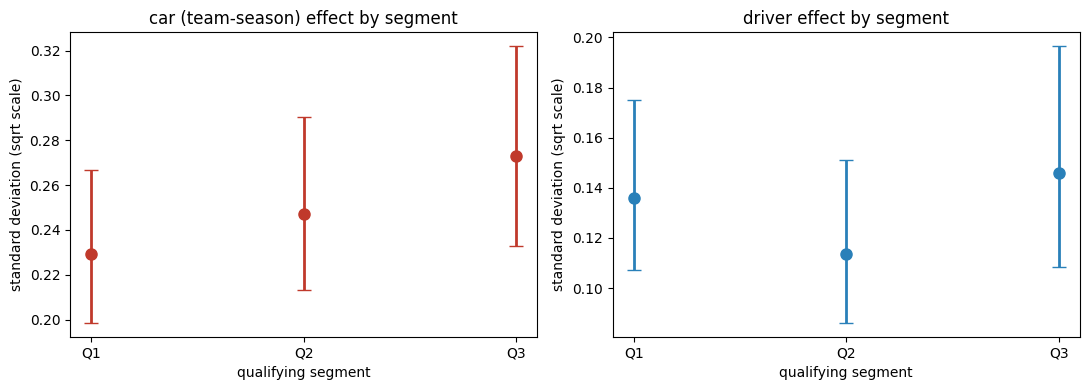

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
positions = range(len(fits))

for ax, (label, prefix, colour) in zip(axes, [('car (team-season)', 'car', '#c0392b'),
                                              ('driver', 'driver', '#2980b9')]):
    ax.errorbar(positions, intervals[f'{prefix}_med'],
                yerr=[intervals[f'{prefix}_med'] - intervals[f'{prefix}_lo'],
                      intervals[f'{prefix}_hi'] - intervals[f'{prefix}_med']],
                fmt='o', capsize=5, color=colour, lw=2, ms=8)
    ax.set_xticks(positions)
    ax.set_xticklabels(intervals.index)
    ax.set_title(f'{label} effect by segment')
    ax.set_ylabel('standard deviation (sqrt scale)')
    ax.set_xlabel('qualifying segment')

plt.tight_layout()
plt.show()

### The prediction holds, without being decisive

| segment | driver effect | car effect |
|---|---|---|
| Q1 | 0.136 [0.107, 0.175] | 0.229 [0.198, 0.267] |
| Q2 | 0.114 [0.086, 0.151] | 0.247 [0.213, 0.291] |
| Q3 | 0.146 [0.108, 0.197] | **0.273** [0.233, 0.322] |

**P(car effect larger in Q3 than Q1) = 0.895.**

The car effect grows steadily as sandbagging falls away, and there's an 89.5% posterior probability
the Q3 figure genuinely exceeds the Q1 one. Driver effects show no such pattern, their intervals sit
almost on top of each other, which is what should happen if sandbagging never distorted within-team
comparisons in the first place.

Two qualifications. **89.5% supports the explanation without proving it**, the intervals do overlap, and a stricter
reader would call this suggestive. And **Q3 isn't a clean measurement** either, since it holds only
the fastest ten drivers.

That second point cuts in favour of the conclusion rather than against it. Restricting to the top ten
should *compress* the spread of car performance, because the worst cars aren't there. The car effect
grows anyway. Whatever is inflating it has to be strong enough to overcome that.

**So notebook 03's 67% figure for the car's share stands as a floor**, exactly as claimed there, and
this is now measured rather than argued.

## The other decisions

Three more choices from earlier notebooks, each refitted on Q1 so the segment stays constant:

- **Wet sessions** were kept, on the grounds that they're real racing. If they're adding noise rather
  than signal, dropping them should change the ratings.
- **The 107% rule** removed 21 rows. Small, but it removed the largest outliers, and those have
  leverage.
- **Sparse drivers** were kept and pooled rather than filtered. If the pooling works correctly,
  removing them should not move the drivers who remain.

In [9]:
q1 = segments['Q1']

variants = {
    'baseline (Q1, 107%)': q1[q1['within_107']],
    'dry sessions only': q1[q1['within_107'] & q1['rain_fraction'].eq(0)],
    'no 107% filter': q1,
    'drivers with 20+ sessions': q1[q1['within_107'] & q1.groupby('drv')['drv']
                                    .transform('size').ge(20)],
}

variant_fits = {'baseline (Q1, 107%)': fits['Q1']}
for label, table in variants.items():
    if label not in variant_fits:
        variant_fits[label] = fit_variant(table, label)

Output()

dry sessions only        rows= 2493  divergences=  0  max R-hat=1.0033


Output()

no 107% filter           rows= 3029  divergences=  0  max R-hat=1.0063


Output()

drivers with 20+ sessions rows= 2892  divergences=  0  max R-hat=1.0053


In [10]:
def driver_effects(fitted):
    posterior = fitted.posterior
    draws = posterior['1|drv'].values.reshape(-1, posterior['1|drv'].shape[-1])
    names = posterior['1|drv'].coords['drv__factor_dim'].values
    return pd.Series(np.median(draws, axis=0), index=names)


baseline_effects = driver_effects(variant_fits['baseline (Q1, 107%)'])

rows = []
for label, fitted in variant_fits.items():
    effects = driver_effects(fitted)
    shared = baseline_effects.index.intersection(effects.index)
    rho = spearmanr(baseline_effects[shared], effects[shared]).statistic
    sizes = effect_sizes(fitted)
    rows.append({
        'variant': label,
        'drivers': len(effects),
        'rank_corr_vs_baseline': rho,
        'driver_sd': sizes['driver_sd'],
        'car_sd': sizes['car_sd'],
        'car_over_driver': sizes['car_over_driver'],
    })

pd.DataFrame(rows).set_index('variant').round(3)

,drivers,rank_corr_vs_baseline,driver_sd,car_sd,car_over_driver
variant,,,,,
"baseline (Q1, 107%)",43,1.000,0.136,0.229,1.687
dry sessions only,43,0.968,0.125,0.229,1.832
no 107% filter,43,0.971,0.161,0.220,1.368
drivers with 20+ sessions,33,0.996,0.143,0.227,1.587


### The ranking holds; the exact ratio doesn't

| variant | rank corr | driver sd | car sd | car ÷ driver |
|---|---|---|---|---|
| baseline (Q1, 107%) | 1.000 | 0.136 | 0.229 | 1.69 |
| dry sessions only | 0.968 | 0.125 | 0.229 | 1.83 |
| no 107% filter | 0.971 | **0.161** | 0.220 | 1.37 |
| drivers with 20+ sessions | 0.996 | 0.143 | 0.227 | 1.59 |

**The driver ranking is essentially fixed.** Rank correlation never drops below 0.968, including when
wet sessions go, when the outlier filter is removed, and when ten drivers are deleted outright.
Whoever is fast stays fast regardless of these choices.

**The car effect barely moves at all**, 0.220 to 0.229 across every variant. Whatever these
decisions affect, it isn't the estimate of how much the machinery matters.

**The 107% filter is the choice that carries weight.** Removing it inflates the driver effect by 18%,
from 0.136 to 0.161, while leaving the car effect alone. This indicates that outliers are being attributed to drivers: a lap 45% off the pace tells you a driver's session went wrong, and without the
filter the model reads it as evidence about how fast that driver is. The car estimate survives
because those laps are scattered across teams rather than concentrated in any one.

That's a retrospective vindication of a decision made in notebook 01 on domain grounds alone, 
borrowing F1's own qualifying threshold rather than inventing a cutoff.

**Sparse drivers turn out not to matter.** Dropping the ten with fewest sessions changes the ranking
of those remaining by almost nothing (ρ = 0.996). Partial pooling was doing exactly what it should:
shrinking thin records toward the mean so they influence little.

## What this means for the headline number

Notebook 03 reported the car as roughly 2.8× the driver in variance terms. On the standard-deviation
scale used here, that's 1.69, and across every variant tested it ranges from **1.37 to 1.83**, or
1.9× to 3.4× in variance terms, reaching 2.18 when fitted on Q2.

So the right statement isn't "the car matters 2.8× more than the driver." It's **"the car matters
roughly two to three times as much as the driver, and that holds under every alternative choice
tested."** The direction never changes. The exact multiple depends on choices another analyst could
reasonably make differently.

## Quantified takeaways

1. **The pre-registered sandbagging test passed.** Notebook 03 predicted that refitting on later
   qualifying segments would spread the car effects while leaving driver effects alone. Car effects
   rose from 0.229 (Q1) to 0.273 (Q3), with **P(Q3 > Q1) = 0.895**, while driver effects showed no
   trend. This supports the explanation without proving it, and the prediction was made before the test.

2. **Selection bias makes that result stronger, not weaker.** Q3 contains only the fastest ten
   drivers, which should compress measured spread. The car effect grew anyway, so whatever inflates
   it is strong enough to overcome a force pushing the other way.

3. **The driver ranking survives everything.** Rank correlation against baseline never falls below
   **0.968**, dropping wet sessions, removing the outlier filter, deleting ten drivers. The ordering
   is a property of the data, not of these decisions.

4. **The 107% filter is the one choice with real leverage.** Removing it inflates the driver effect
   by 18% (0.136 → 0.161) while leaving the car effect untouched, because outlier laps get read as
   evidence about driver speed. A decision made on domain grounds in notebook 01 turns out to have
   been the consequential one.

5. **Partial pooling works as advertised.** Deleting the ten drivers with the thinnest records
   changes the remaining ranking by almost nothing (ρ = 0.996). The sparse drivers were already
   contributing little, exactly as the shrinkage intended.

6. **The headline is a range, not a single number.** Across every variant the car-to-driver ratio runs
   from 1.37 to 1.83 on the standard-deviation scale, roughly **two to three times** in variance
   terms. The direction is never in doubt; the exact multiple depends on choices a reasonable analyst
   could make differently.